In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns


In [2]:
train = pd.read_csv('train.csv')

In [3]:
test = pd.read_csv('test.csv')

In [4]:
train.sample(10)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
159,160,60,RL,134.0,19378,Pave,NaN,IR1,HLS,AllPub,...,0,NaN,NaN,NaN,0,3,2006,New,Partial,320000
167,168,60,RL,86.0,10562,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,11,2007,New,Partial,325624
1287,1288,20,RL,NaN,36500,Pave,NaN,IR1,Low,AllPub,...,0,NaN,NaN,NaN,0,6,2006,WD,Normal,190000
1126,1127,120,RL,53.0,3684,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2009,WD,Normal,174000
652,653,60,RL,70.0,8750,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,191000
71,72,20,RL,69.0,7599,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2007,WD,Normal,129500
238,239,20,RL,93.0,12030,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2007,New,Partial,318000
643,644,60,RL,80.0,10793,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdWo,NaN,0,4,2007,WD,Normal,152000
995,996,50,RL,51.0,4712,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2006,WD,Abnorml,121600
58,59,60,RL,66.0,13682,Pave,NaN,IR2,HLS,AllPub,...,0,NaN,NaN,NaN,0,10,2006,New,Partial,438780


In [5]:
train.shape

(1460, 81)

In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [7]:
train.isnull().sum()[train.isnull().sum()>0]

LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64

In [8]:
# Alley , MasVnrType , FireplaceQu , PoolQC , Fence , MiscFeature 

In [9]:
train = train.drop(['Alley' , 'MasVnrType' , 'FireplaceQu' , 'PoolQC' , 'Fence' , 'MiscFeature' ],axis=1)
test = test.drop(['Alley' , 'MasVnrType' , 'FireplaceQu' , 'PoolQC' , 'Fence' , 'MiscFeature' ],axis=1)

In [10]:
train.shape

(1460, 75)

In [11]:
train.sample(5)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,...,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
321,322,60,RL,99.0,12099,Pave,IR1,Lvl,AllPub,Inside,...,0,0,0,0,0,6,2007,WD,Normal,354000
1335,1336,20,RL,80.0,9650,Pave,Reg,Lvl,AllPub,Inside,...,0,0,0,0,0,4,2009,WD,Normal,167900
925,926,20,RL,NaN,15611,Pave,IR1,Lvl,AllPub,Corner,...,0,0,0,0,0,3,2008,WD,Abnorml,175000
169,170,20,RL,NaN,16669,Pave,IR1,Lvl,AllPub,Corner,...,0,0,0,0,0,1,2006,WD,Normal,228000
1409,1410,60,RL,46.0,20544,Pave,IR1,Lvl,AllPub,CulDSac,...,0,0,0,0,0,11,2008,WD,Normal,215000


In [12]:
pd.set_option('display.max_columns', None)

In [13]:
train['LotShape'].value_counts()

LotShape
Reg    925
IR1    484
IR2     41
IR3     10
Name: count, dtype: int64

In [14]:
train['Street'].value_counts()

Street
Pave    1454
Grvl       6
Name: count, dtype: int64

In [15]:
train.corr(numeric_only=True)

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,1.000000,0.011156,-0.010601,-0.033226,-0.028365,0.012609,-0.012713,-0.021998,-0.050298,-0.005024,-0.005968,-0.007940,-0.015415,0.010496,0.005590,-0.044230,0.008273,0.002289,-0.020155,0.005587,0.006784,0.037719,0.002951,0.027239,-0.019772,0.000072,0.016570,0.017634,-0.029643,-0.000477,0.002889,-0.046635,0.001330,0.057044,-0.006242,0.021172,0.000712,-0.021917
MSSubClass,0.011156,1.000000,-0.386347,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.022936,-0.069836,-0.065649,-0.140759,-0.238518,-0.251758,0.307886,0.046474,0.074853,0.003491,-0.002333,0.131608,0.177354,-0.023438,0.281721,0.040380,-0.045569,0.085072,-0.040110,-0.098672,-0.012579,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284
LotFrontage,-0.010601,-0.386347,1.000000,0.426095,0.251646,-0.059213,0.123349,0.088866,0.193458,0.233633,0.049900,0.132644,0.392075,0.457181,0.080177,0.038469,0.402797,0.100949,-0.007234,0.198769,0.053532,0.263170,-0.006069,0.352096,0.266639,0.070250,0.285691,0.344997,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,-0.033226,-0.139781,0.426095,1.000000,0.105806,-0.005636,0.014228,0.013788,0.104160,0.214103,0.111170,-0.002618,0.260833,0.299475,0.050986,0.004779,0.263116,0.158155,0.048046,0.126031,0.014259,0.119690,-0.017784,0.190015,0.271364,-0.024947,0.154871,0.180403,0.171698,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843
OverallQual,-0.028365,0.032628,0.251646,0.105806,1.000000,-0.091932,0.572323,0.550684,0.411876,0.239666,-0.059119,0.308159,0.537808,0.476224,0.295493,-0.030429,0.593007,0.111098,-0.040150,0.550600,0.273458,0.101676,-0.183882,0.427452,0.396765,0.547766,0.600671,0.562022,0.238923,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982
OverallCond,0.012609,-0.059316,-0.059213,-0.005636,-0.091932,1.000000,-0.375983,0.073741,-0.128101,-0.046231,0.040229,-0.136841,-0.171098,-0.144203,0.028942,0.025494,-0.079686,-0.054942,0.117821,-0.194149,-0.060769,0.012980,-0.087001,-0.057583,-0.023820,-0.324297,-0.185758,-0.151521,-0.003334,-0.032589,0.070356,0.025504,0.054811,-0.001985,0.068777,-0.003511,0.043950,-0.077856
YearBuilt,-0.012713,0.027850,0.123349,0.014228,0.572323,-0.375983,1.000000,0.592855,0.315707,0.249503,-0.049107,0.149040,0.391452,0.281986,0.010308,-0.183784,0.199010,0.187599,-0.038162,0.468271,0.242656,-0.070651,-0.174800,0.095589,0.147716,0.825667,0.537850,0.478954,0.224880,0.188686,-0.387268,0.031355,-0.050364,0.004950,-0.034383,0.012398,-0.013618,0.522897
YearRemodAdd,-0.021998,0.040581,0.088866,0.013788,0.550684,0.073741,0.592855,1.000000,0.179618,0.128451,-0.067759,0.181133,0.291066,0.240379,0.140024,-0.062419,0.287389,0.119470,-0.012337,0.439046,0.183331,-0.040581,-0.149598,0.191740,0.112581,0.642277,0.420622,0.371600,0.205726,0.226298,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743,0.507101
MasVnrArea,-0.050298,0.022936,0.193458,0.104160,0.411876,-0.128101,0.315707,0.179618,1.000000,0.264736,-0.072319,0.114442,0.363936,0.344501,0.174561,-0.069071,0.390857,0.085310,0.026673,0.276833,0.201444,0.102821,-0.037610,0.280682,0.249070,0.252691,0.364204,0.373066,0.159718,0.125703,-0.110204,0.018796,0.061466,0.011723,-0.029815,-0.005965,-0.008201,0.477493
BsmtFinSF1,-0.005024,-0.069836,0.233633,0.214103,0.239666,-0.046231,0.249503,0.128451,0.264736,1.000000,-0.050117,-0.495251,0.522396,0.445863,-0.137079,-0.064503,0.208171,0.649212,0.067418,0.058543,0.004262,-0.107355,-0.081007,0.044316,0.260011,0.153484,0.224054,0.296970,0.204306,0.111761,-0.102303,0.026451

<Axes: >

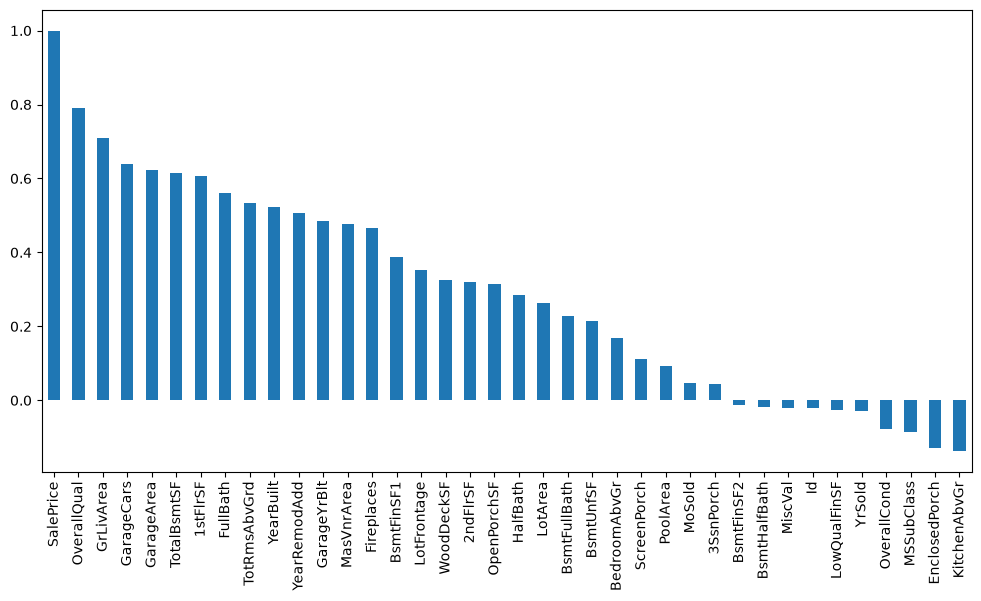

In [16]:
train.corr(numeric_only=True)['SalePrice'].sort_values(ascending=False).plot(kind='bar',figsize=(12,6))

In [17]:
train.select_dtypes(include='object').columns.tolist()

['MSZoning',
 'Street',
 'LotShape',
 'LandContour',
 'Utilities',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BldgType',
 'HouseStyle',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'ExterQual',
 'ExterCond',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'Heating',
 'HeatingQC',
 'CentralAir',
 'Electrical',
 'KitchenQual',
 'Functional',
 'GarageType',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'PavedDrive',
 'SaleType',
 'SaleCondition']

In [18]:
#from ydata_profiling import ProfileReport

In [19]:
'''profile = ProfileReport(train, title="Data Report")
profile.to_file("my_data_report.html")'''


'profile = ProfileReport(train, title="Data Report")\nprofile.to_file("my_data_report.html")'

In [20]:
train = train.drop(columns=['Id','Street','Utilities','Condition2','RoofMatl','Condition1','BsmtFinType2','BsmtFinSF2','Heating','Electrical','LowQualFinSF','BsmtHalfBath','GarageCond','PavedDrive','OpenPorchSF','EnclosedPorch','3SsnPorch','ScreenPorch','PoolArea','MiscVal','MoSold','YrSold'])
test = test.drop(columns=['Id','Street','Utilities','Condition2','RoofMatl','Condition1','BsmtFinType2','BsmtFinSF2','Heating','Electrical','LowQualFinSF','BsmtHalfBath','GarageCond','PavedDrive','OpenPorchSF','EnclosedPorch','3SsnPorch','ScreenPorch','PoolArea','MiscVal','MoSold','YrSold'])

In [21]:
train.shape

(1460, 53)

In [22]:
test.shape

(1459, 52)

In [23]:
train.sample(5)

,MSSubClass,MSZoning,LotFrontage,LotArea,LotShape,LandContour,LotConfig,LandSlope,Neighborhood,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,Exterior1st,Exterior2nd,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtUnfSF,TotalBsmtSF,HeatingQC,CentralAir,1stFlrSF,2ndFlrSF,GrLivArea,BsmtFullBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,WoodDeckSF,SaleType,SaleCondition,SalePrice
30,70,C (all),50.0,8500,Reg,Lvl,Inside,Gtl,IDOTRR,1Fam,2Story,4,4,1920,1950,Gambrel,BrkFace,BrkFace,0.0,TA,Fa,BrkTil,TA,TA,No,Unf,0,649,649,TA,N,649,668,1317,0,1,0,3,1,TA,6,Typ,0,Detchd,1920.0,Unf,1,250,TA,0,WD,Normal,40000
988,60,RL,NaN,12046,IR1,Lvl,Inside,Gtl,NWAmes,1Fam,2Story,6,6,1976,1976,Gable,Plywood,Plywood,298.0,TA,TA,CBlock,TA,TA,No,LwQ,156,692,848,TA,Y,1118,912,2030,0,2,1,4,1,Gd,8,Typ,1,Attchd,1976.0,Fin,2,551,TA,0,WD,Normal,195000
50,60,RL,NaN,13869,IR2,Lvl,Corner,Gtl,Gilbert,1Fam,2Story,6,6,1997,1997,Gable,VinylSd,VinylSd,0.0,TA,TA,PConc,Gd,TA,Av,GLQ,182,612,794,Gd,Y,794,676,1470,0,2,0,3,1,TA,6,Typ,0,Attchd,1997.0,Fin,2,388,TA,0,WD,Normal,177000
337,20,RL,70.0,9135,Reg,Lvl,Inside,Gtl,CollgCr,1Fam,1Story,7,5,2002,2003,Gable,VinylSd,VinylSd,113.0,Gd,TA,PConc,Gd,TA,Av,GLQ,810,726,1536,Ex,Y,1536,0,1536,1,2,0,3,1,Gd,7,Typ,0,Attchd,2002.0,RFn,2,532,TA,192,WD,Normal,214000
1119,20,RL,70.0,7560,Reg,Lvl,Inside,Gtl,NAmes,1Fam,1Story,5,5,1959,1959,Gable,BrkFace,Wd Sdng,0.0,TA,TA,CBlock,TA,TA,No,LwQ,369,671,1040,TA,Y,1040,0,1040,0,1,0,3,1,TA,6,Typ,0,Attchd,1959.0,RFn,1,286,TA,140,WD,Normal,133700


In [24]:
'''profile = ProfileReport(train, title="Data Report")
profile.to_file("after_column_removed.html")'''

'profile = ProfileReport(train, title="Data Report")\nprofile.to_file("after_column_removed.html")'

In [25]:
train[train.isnull().any(axis=1)]

,MSSubClass,MSZoning,LotFrontage,LotArea,LotShape,LandContour,LotConfig,LandSlope,Neighborhood,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,Exterior1st,Exterior2nd,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtUnfSF,TotalBsmtSF,HeatingQC,CentralAir,1stFlrSF,2ndFlrSF,GrLivArea,BsmtFullBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,WoodDeckSF,SaleType,SaleCondition,SalePrice
7,60,RL,NaN,10382,IR1,Lvl,Corner,Gtl,NWAmes,1Fam,2Story,7,6,1973,1973,Gable,HdBoard,HdBoard,240.0,TA,TA,CBlock,Gd,TA,Mn,ALQ,859,216,1107,Ex,Y,1107,983,2090,1,2,1,3,1,TA,7,Typ,2,Attchd,1973.0,RFn,2,484,TA,235,WD,Normal,200000
12,20,RL,NaN,12968,IR2,Lvl,Inside,Gtl,Sawyer,1Fam,1Story,5,6,1962,1962,Hip,HdBoard,Plywood,0.0,TA,TA,CBlock,TA,TA,No,ALQ,737,175,912,TA,Y,912,0,912,1,1,0,2,1,TA,4,Typ,0,Detchd,1962.0,Unf,1,352,TA,140,WD,Normal,144000
14,20,RL,NaN,10920,IR1,Lvl,Corner,Gtl,NAmes,1Fam,1Story,6,5,1960,1960,Hip,MetalSd,MetalSd,212.0,TA,TA,CBlock,TA,TA,No,BLQ,733,520,1253,TA,Y,1253,0,1253,1,1,1,2,1,TA,5,Typ,1,Attchd,1960.0,RFn,1,352,TA,0,WD,Normal,157000
16,20,RL,NaN,11241,IR1,Lvl,CulDSac,Gtl,NAmes,1Fam,1Story,6,7,1970,1970,Gable,Wd Sdng,Wd Sdng,180.0,TA,TA,CBlock,TA,TA,No,ALQ,578,426,1004,Ex,Y,1004,0,1004,1,1,0,2,1,TA,5,Typ,1,Attchd,1970.0,Fin,2,480,TA,0,WD,Normal,149000
17,90,RL,72.0,10791,Reg,Lvl,Inside,Gtl,Sawyer,Duplex,1Story,4,5,1967,1967,Gable,MetalSd,MetalSd,0.0,TA,TA,Slab,NaN,NaN,NaN,NaN,0,0,0,TA,Y,1296,0,1296,0,2,0,2,2,TA,6,Typ,0,CarPort,1967.0,Unf,2,516,TA,0,WD,Normal,90000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1443,30,RL,NaN,8854,Reg,Lvl,Inside,Gtl,BrkSide,1Fam,1.5Unf,6,6,1916,1950,Gable,Wd Sdng,Wd Sdng,0.0,TA,TA,BrkTil,TA,TA,No,Unf,0,952,952,Fa,N,952,0,952,0,1,0,2,1,Fa,4,Typ,1,Detchd,1916.0,Unf,1,192,Fa,0,WD,Normal,121000
1446,20,RL,NaN,26142,IR1,Lvl,CulDSac,Gtl,Mitchel,1Fam,1Story,5,7,1962,1962,Gable,HdBoard,HdBoard,189.0,TA,TA,CBlock,TA,TA,No,Rec,593,595,1188,TA,Y,1188,0,1188,0,1,0,3,1,TA,6,Typ,0,Attchd,1962.0,Unf,1,312,TA,261,WD,Normal,157900
1449,180,RM,21.0,1533,Reg,Lvl,Inside,Gtl,MeadowV,Twnhs,SFoyer,5,7,1970,1970,Gable,CemntBd,CmentBd,0.0,TA,TA,CBlock,Gd,TA,Av,GLQ,553,77,630,Ex,Y,630,0,630,1,1,0,1,1,Ex,3,Typ,0,NaN,NaN,NaN,0,0,NaN,0,WD,Abnorml,92000
1450,90,RL,60.0,9000,Reg,Lvl,FR2,Gtl,NAmes,Duplex,2Story,5,5,1974,1974,Gable,VinylSd,VinylSd,0.0,TA,TA,CBlock,Gd,TA,No,Unf,0,896,896,TA,Y,896,896,1792,0,2,2,4,2,TA,8,Typ,0,NaN,NaN,NaN,0,0,NaN,32,WD,Normal,136000


In [26]:
numeric_feature = train[['MSSubClass',
 'LotArea',
 'OverallQual',
 'OverallCond',
 'YearBuilt',
 'YearRemodAdd',
 'BsmtFinSF1',
 'BsmtUnfSF',
 'TotalBsmtSF',
 '1stFlrSF',
 '2ndFlrSF',
 'GrLivArea',
 'BsmtFullBath',
 'FullBath',
 'HalfBath',
 'BedroomAbvGr',
 'KitchenAbvGr',
 'TotRmsAbvGrd',
 'Fireplaces',
 'GarageCars',
 'GarageArea',
 'WoodDeckSF','LotFrontage', 'MasVnrArea', 'GarageYrBlt']]

In [27]:
train.select_dtypes(include='float').columns.tolist()

['LotFrontage', 'MasVnrArea', 'GarageYrBlt']

In [28]:
categorical_feature = train[['MSZoning',
 'LotShape',
 'LandContour',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'BldgType',
 'HouseStyle',
 'RoofStyle',
 'Exterior1st',
 'Exterior2nd',
 'ExterQual',
 'ExterCond',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'HeatingQC',
 'CentralAir',
 'KitchenQual',
 'Functional',
 'GarageType',
 'GarageFinish',
 'GarageQual',
 'SaleType',
 'SaleCondition']]


In [29]:
numeric_feature = numeric_feature.columns.tolist()

In [30]:
categorical_feature = categorical_feature.columns.tolist()

In [31]:
from sklearn.model_selection import train_test_split

In [32]:
x = train.iloc[:,:-1]
y = train.iloc[:,-1]

In [33]:
x_train , x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [34]:
x_train.shape

(1168, 52)

In [35]:
x_test.shape

(292, 52)

In [36]:
from sklearn.impute import SimpleImputer

In [37]:
num_feat = SimpleImputer(strategy='median')

x_train[numeric_feature] = num_feat.fit_transform(x_train[numeric_feature])
x_test[numeric_feature] = num_feat.transform(x_test[numeric_feature])

In [38]:
cat_feat = SimpleImputer(strategy='most_frequent')

x_train[categorical_feature] = cat_feat.fit_transform(x_train[categorical_feature])
x_test[categorical_feature] = cat_feat.transform(x_test[categorical_feature])

In [39]:
test[numeric_feature] = num_feat.transform(test[numeric_feature])
test[categorical_feature] = cat_feat.transform(test[categorical_feature])

In [40]:
x_train.sample(10)

,MSSubClass,MSZoning,LotFrontage,LotArea,LotShape,LandContour,LotConfig,LandSlope,Neighborhood,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,Exterior1st,Exterior2nd,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtUnfSF,TotalBsmtSF,HeatingQC,CentralAir,1stFlrSF,2ndFlrSF,GrLivArea,BsmtFullBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,WoodDeckSF,SaleType,SaleCondition
854,20.0,RL,102.0,17920.0,Reg,Lvl,Inside,Gtl,Sawyer,1Fam,1Story,5.0,4.0,1955.0,1974.0,Hip,Wd Sdng,Plywood,0.0,TA,TA,CBlock,TA,TA,Mn,ALQ,306.0,372.0,1763.0,TA,Y,1779.0,0.0,1779.0,1.0,1.0,1.0,3.0,1.0,TA,6.0,Typ,1.0,Attchd,1955.0,Unf,2.0,454.0,TA,0.0,WD,Abnorml
460,60.0,FV,75.0,8004.0,IR1,Lvl,Inside,Gtl,Somerst,1Fam,2Story,8.0,5.0,2009.0,2009.0,Gable,VinylSd,VinylSd,110.0,Gd,TA,PConc,Gd,TA,No,GLQ,544.0,288.0,832.0,Ex,Y,832.0,1103.0,1935.0,1.0,2.0,1.0,3.0,1.0,TA,8.0,Typ,0.0,BuiltIn,2009.0,Fin,2.0,552.0,TA,0.0,New,Partial
1231,90.0,RL,70.0,7728.0,Reg,Lvl,Inside,Gtl,NAmes,Duplex,SLvl,5.0,6.0,1962.0,1962.0,Hip,Wd Sdng,Wd Sdng,120.0,TA,TA,CBlock,TA,TA,Av,ALQ,803.0,303.0,1106.0,TA,Y,1190.0,0.0,1190.0,1.0,1.0,0.0,3.0,1.0,TA,6.0,Typ,0.0,Attchd,1962.0,Unf,2.0,540.0,TA,0.0,WD,Normal
779,90.0,RL,78.0,10530.0,Reg,Lvl,Inside,Gtl,Mitchel,Duplex,SFoyer,6.0,5.0,1977.0,1977.0,Gable,Plywood,ImStucc,90.0,TA,TA,CBlock,Gd,TA,Gd,GLQ,975.0,0.0,975.0,TA,Y,1004.0,0.0,1004.0,1.0,1.0,0.0,2.0,1.0,TA,4.0,Typ,0.0,Attchd,1977.0,Unf,2.0,504.0,TA,0.0,WD,Normal
1214,85.0,RL,69.0,10205.0,IR1,Lvl,Inside,Gtl,NAmes,1Fam,SFoyer,5.0,5.0,1962.0,1962.0,Gable,MetalSd,MetalSd,0.0,TA,TA,CBlock,TA,TA,Av,BLQ,784.0,141.0,925.0,TA,Y,999.0,0.0,999.0,1.0,1.0,0.0,3.0,1.0,TA,6.0,Typ,0.0,Attchd,1962.0,Unf,1.0,300.0,TA,150.0,WD,Normal
536,60.0,RL,57.0,8924.0,IR1,Lvl,CulDSac,Gtl,CollgCr,1Fam,2Story,7.0,5.0,1998.0,1999.0,Gable,VinylSd,VinylSd,0.0,TA,TA,PConc,Gd,TA,Av,Unf,0.0,880.0,880.0,Ex,Y,880.0,844.0,1724.0,0.0,2.0,1.0,3.0,1.0,Gd,8.0,Typ,0.0,Attchd,1998.0,Fin,2.0,527.0,TA,120.0,WD,Normal
61,75.0,RM,60.0,7200.0,Reg,Lvl,Inside,Gtl,IDOTRR,1Fam,2.5Unf,5.0,7.0,1920.0,1996.0,Gable,MetalSd,MetalSd,0.0,TA,TA,BrkTil,TA,Fa,No,Unf,0.0,530.0,530.0,TA,N,581.0,530.0,1111.0,0.0,1.0,0.0,3.0,1.0,Fa,6.0,Typ,0.0,Detchd,1935.0,Unf,1.0,288.0,TA,0.0,WD,Normal
987,20.0,RL,83.0,10159.0,IR1,Lvl,Inside,Gtl,NridgHt,1Fam,1Story,9.0,5.0,2009.0,2010.0,Hip,VinylSd,VinylSd,450.0,Ex,TA,PConc,Ex,TA,Av,GLQ,1646.0,284.0,1930.0,Ex,Y,1940.0,0.0,1940.0,1.0,2.0,1.0,3.0,1.0,Ex,8.0,Typ,1.0,Attchd,2010.0,Fin,3.0,606.0,TA,168.0,New,Partial
1037,60.0,RL,70.0,9240.0,Reg,Lvl,Inside,Gtl,CollgCr,1Fam,2Story,8.0,5.0,2001.0,2002.0,Gable,VinylSd,VinylSd,396.0,Gd,TA,PConc,Gd,TA,No,Unf,0.0,1055.0,1055.0,Ex,Y,1055.0,1208.0,2263.0,0.0,2.0,1.0,3.0,1.0,Gd,7.0,Typ,1.0,BuiltIn,2001.0,Fin,2.0,905.0,TA,0.0,WD,Normal
1238,20.0,RL,63.0,13072.0,Reg,Lvl,Inside,Gtl,SawyerW,1Fam,1Story,6.0,5.0,2005.0,2005.0,Gable,VinylSd,VinylSd,0.0,Gd,TA,PConc,Gd,TA,No,Unf,0.0,1141.0,1141.0,Ex,Y,1141.0,0.0,1141.0,0.0,1.0,1.0,3.0,1.0,TA,6.0,Typ,0.0,Detchd,2005.0,Unf,2.0,484.0,TA,0.0,WD,Abnorml


In [41]:
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder

In [42]:
ohe = OneHotEncoder(drop='first',dtype=np.int32,sparse_output=False,handle_unknown='ignore')

In [43]:
ordinal_feat = x_train[['LotShape','HouseStyle','ExterQual','ExterCond','BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1','HeatingQC','CentralAir','KitchenQual','Functional','GarageFinish','GarageQual']]

In [44]:
ohe_feat =  x_train[['MSZoning','LandContour','LotConfig','LandSlope','Neighborhood','BldgType','RoofStyle','Exterior1st','Exterior2nd','Foundation','GarageType','SaleType','SaleCondition']]

In [45]:
ordinal_feat=ordinal_feat.columns.to_list()

In [46]:
ohe_feat = ohe_feat.columns.to_list()

In [47]:
x_train_ohe = ohe.fit_transform(x_train[ohe_feat])
x_train_ohe = pd.DataFrame(x_train_ohe,columns = ohe.get_feature_names_out(ohe_feat),
                          index=x_train.index)

In [48]:
x_test_ohe = ohe.transform(x_test[ohe_feat])
x_test_ohe = pd.DataFrame(x_test_ohe,columns = ohe.get_feature_names_out(ohe_feat),
                          index=x_test.index)

In [49]:
test_ohe = ohe.transform(test[ohe_feat])
test_ohe = pd.DataFrame(test_ohe,columns = ohe.get_feature_names_out(ohe_feat),
                          index=test.index)

In [50]:
categories = [
    ['IR3','IR2','IR1','Reg'],
    ['1Story','1.5Unf','1.5Fin','SFoyer','SLvl','2Story','2.5Unf','2.5Fin'],
    ['Fa','TA','Gd','Ex'],
    ['Po','Fa','TA','Gd','Ex'],
    ['Fa','TA','Gd','Ex'],
    ['Po','Fa','TA','Gd'],
    ['No','Mn','Av','Gd'],
    ['Unf','LwQ','Rec','BLQ','AlQ','GLQ'], 
    ['Po','Fa','TA','Gd','Ex'], 
    ['False','True'],
    ['Fa','Ta','Gd','Ex'],
    ['Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'], 
    ['Unf','Rfn','Fin'], 
    ['Po','Fa','TA','Gd','Ex']
]

In [51]:
ord_enc = OrdinalEncoder(categories=categories , handle_unknown='use_encoded_value',unknown_value=-1)

In [52]:
x_train_ord = ord_enc.fit_transform(x_train[ordinal_feat])
x_train_ord = pd.DataFrame(x_train_ord,columns=ord_enc.get_feature_names_out(ordinal_feat),
                          index=x_train.index)

In [53]:
x_test_ord = ord_enc.transform(x_test[ordinal_feat])
x_test_ord = pd.DataFrame(x_test_ord,columns=ord_enc.get_feature_names_out(ordinal_feat),
                          index=x_test.index)

In [54]:
test_ord = ord_enc.transform(test[ordinal_feat])
test_ord = pd.DataFrame(test_ord,columns=ord_enc.get_feature_names_out(ordinal_feat),
                          index=test.index)

In [55]:

x_train = pd.concat(
    [x_train.drop(columns=ordinal_feat), x_train_ord],
    axis=1
)

x_train = pd.concat(
    [x_train.drop(columns=ohe_feat), x_train_ohe],
    axis=1
)

In [56]:
x_test = pd.concat(
    [x_test.drop(columns=ordinal_feat), x_test_ord],
    axis=1
)

x_test = pd.concat(
    [x_test.drop(columns=ohe_feat), x_test_ohe],
    axis=1
)

In [57]:
test = pd.concat(
    [test.drop(columns=ordinal_feat), test_ord],
    axis=1
)

test = pd.concat(
    [test.drop(columns=ohe_feat), test_ohe],
    axis=1
)

In [58]:
x_train


,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,GrLivArea,BsmtFullBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,LotShape,HouseStyle,ExterQual,ExterCond,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,HeatingQC,CentralAir,KitchenQual,Functional,GarageFinish,GarageQual,MSZoning_FV,MSZoning_RH,MSZoning_RL,MSZoning_RM,LandContour_HLS,LandContour_Low,LandContour_Lvl,LotConfig_CulDSac,LotConfig_FR2,LotConfig_FR3,LotConfig_Inside,LandSlope_Mod,LandSlope_Sev,Neighborhood_Blueste,Neighborhood_BrDale,Neighborhood_BrkSide,Neighborhood_ClearCr,Neighborhood_CollgCr,Neighborhood_Crawfor,Neighborhood_Edwards,Neighborhood_Gilbert,Neighborhood_IDOTRR,Neighborhood_MeadowV,Neighborhood_Mitchel,Neighborhood_NAmes,Neighborhood_NPkVill,Neighborhood_NWAmes,Neighborhood_NoRidge,Neighborhood_NridgHt,Neighborhood_OldTown,Neighborhood_SWISU,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker,BldgType_2fmCon,BldgType_Duplex,BldgType_Twnhs,BldgType_TwnhsE,RoofStyle_Gable,RoofStyle_Gambrel,RoofStyle_Hip,RoofStyle_Mansard,RoofStyle_Shed,Exterior1st_AsphShn,Exterior1st_BrkComm,Exterior1st_BrkFace,Exterior1st_CBlock,Exterior1st_CemntBd,Exterior1st_HdBoard,Exterior1st_ImStucc,Exterior1st_MetalSd,Exterior1st_Plywood,Exterior1st_Stone,Exterior1st_Stucco,Exterior1st_VinylSd,Exterior1st_Wd Sdng,Exterior1st_WdShing,Exterior2nd_AsphShn,Exterior2nd_Brk Cmn,Exterior2nd_BrkFace,Exterior2nd_CBlock,Exterior2nd_CmentBd,Exterior2nd_HdBoard,Exterior2nd_ImStucc,Exterior2nd_MetalSd,Exterior2nd_Other,Exterior2nd_Plywood,Exterior2nd_Stone,Exterior2nd_Stucco,Exterior2nd_VinylSd,Exterior2nd_Wd Sdng,Exterior2nd_Wd Shng,Foundation_CBlock,Foundation_PConc,Foundation_Slab,Foundation_Stone,Foundation_Wood,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_CarPort,GarageType_Detchd,SaleType_CWD,SaleType_Con,SaleType_ConLD,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
254,20.0,70.0,8400.0,5.0,6.0,1957.0,1957.0,0.0,922.0,392.0,1314.0,1314.0,0.0,1314.0,1.0,1.0,0.0,3.0,1.0,5.0,0.0,1957.0,1.0,294.0,250.0,3.0,0.0,1.0,3.0,1.0,2.0,0.0,2.0,2.0,-1.0,-1.0,6.0,-1.0,2.0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
1066,60.0,59.0,7837.0,6.0,7.0,1993.0,1994.0,0.0,0.0,799.0,799.0,799.0,772.0,1571.0,0.0,2.0,1.0,3.0,1.0,7.0,1.0,1993.0,2.0,380.0,0.0,2.0,5.0,2.0,2.0,2.0,2.0,0.0,0.0,3.0,-1.0,-1.0,6.0,-1.0,2.0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
638,30.0,67.0,8777.0,5.0,7.0,1910.0,1950.0,0.0,0.0,796.0,796.0,796.0,0.0,796.0,0.0,1.0,0.0,2.0,1.0,4.0,0.0,1980.0,0.0,0.0,328.0,3.0,0.0,1.0,2.0,0.0,2.0,0.0,0.0,3.0,-1.0,-1.0,6.0,0.0,2.0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
799,50.0,60.0,7200.0,5.0,7.0,1937.0,1950.0,252.0,569.0,162.0,731.0,981.0,787.0,1768.0,1.0,1.0,1.0,3.0,1.0,7.0,2.0,1939.0,1.0,240.0,0.0,3.0,2.0,1.0,2.0,2.0,2.0,0.0,-1.0,4.0,-1.0,2.0,6.0,0.0,2.0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0
380,50.0,50.0,5000.0,5.0,6.0,1924.0,1950.0,0.0,218.0,808.0,1026.0,1026.0,665.0,1691.0,0.0,2.0,0.0,3.0,1.0,6.0,1.0,1924.0,1.0,308.0,0.0,3.0,2.0,1.0,2.0,1.0,2.0,0.0,1.0,2.0,-1.0,2.0,6.0,0.0,2.0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,

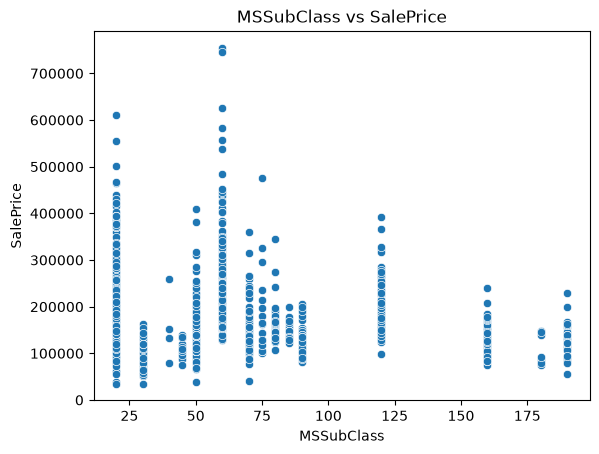

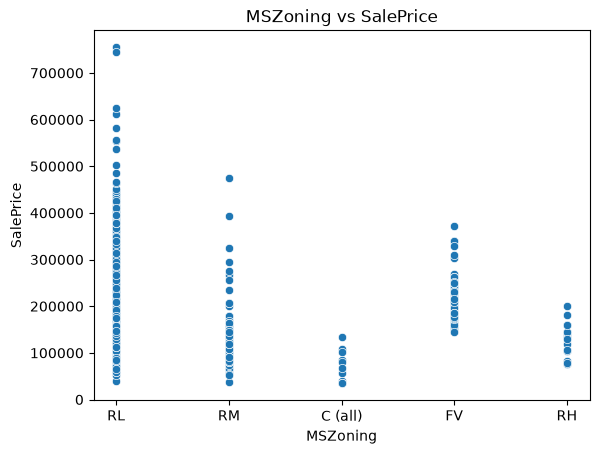

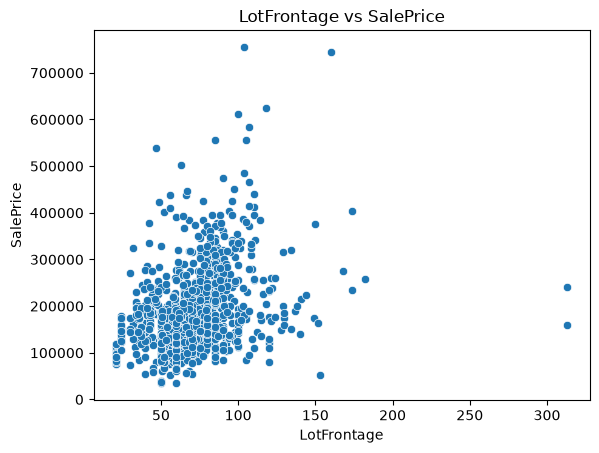

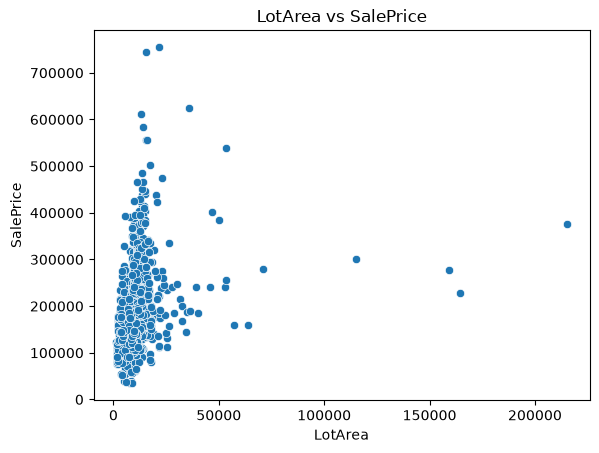

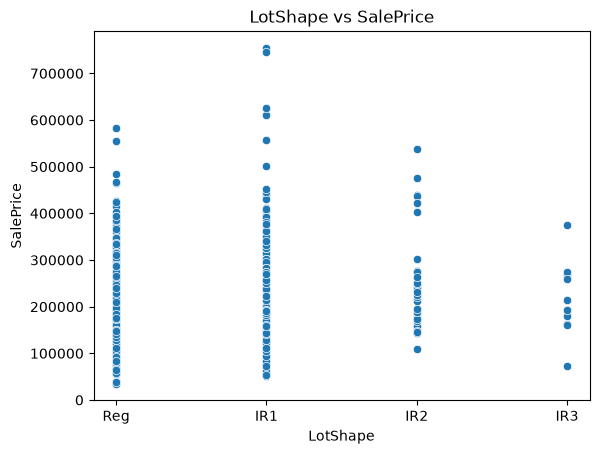

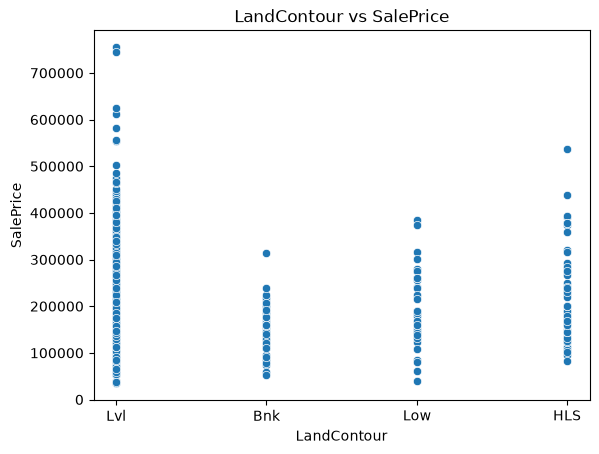

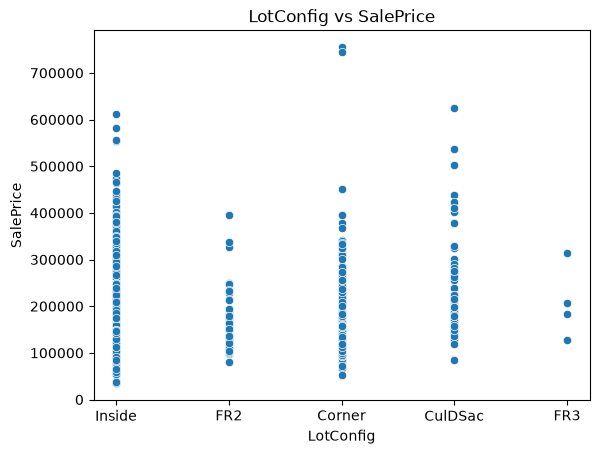

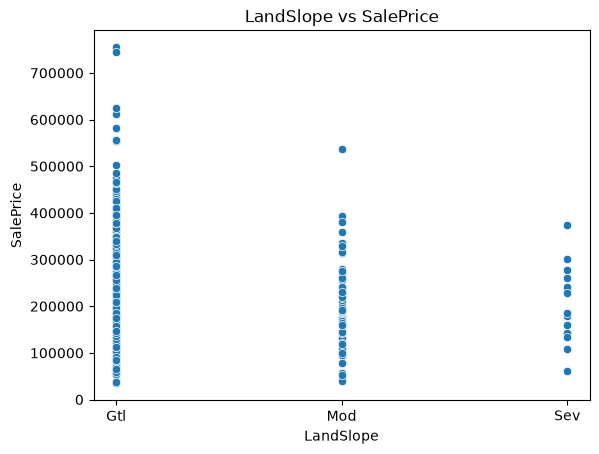

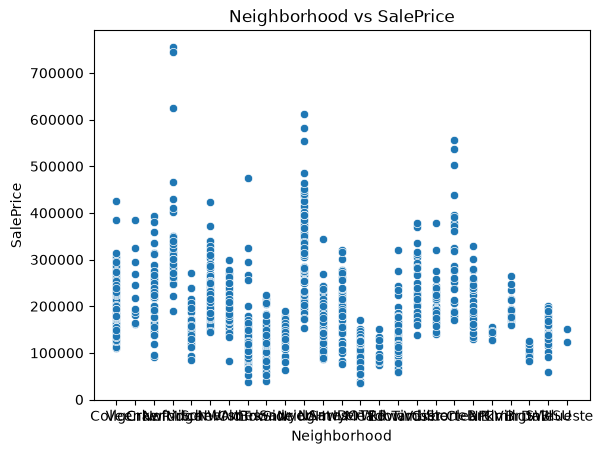

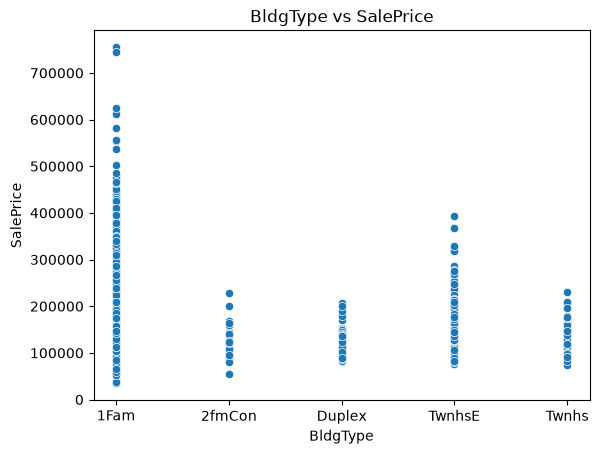

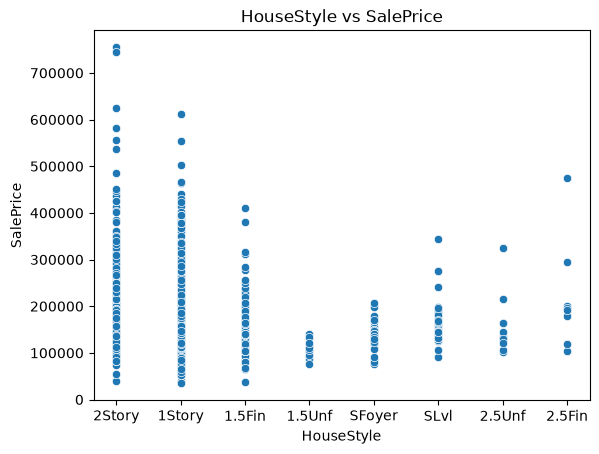

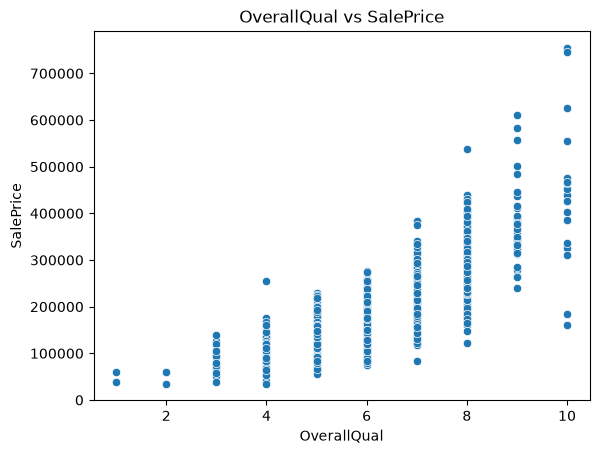

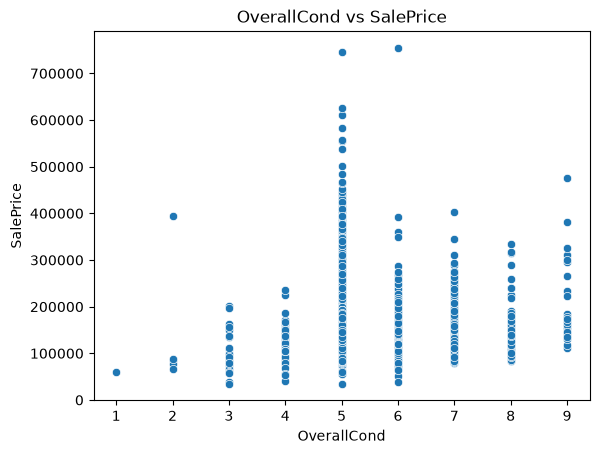

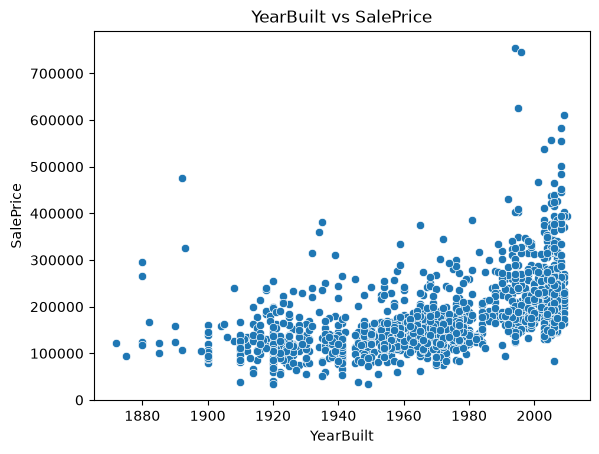

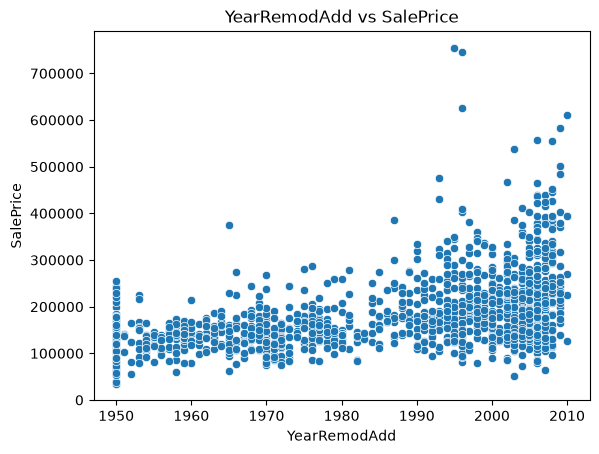

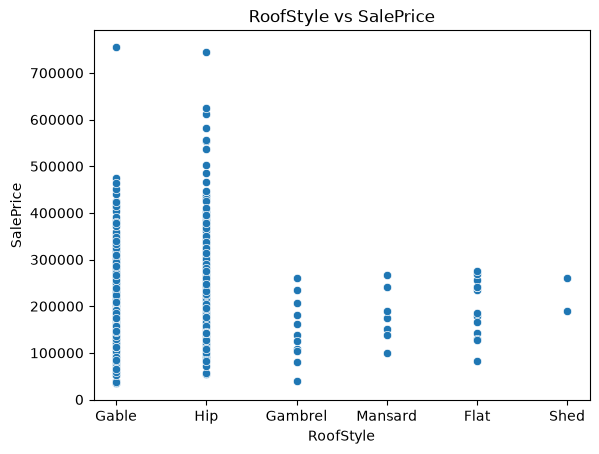

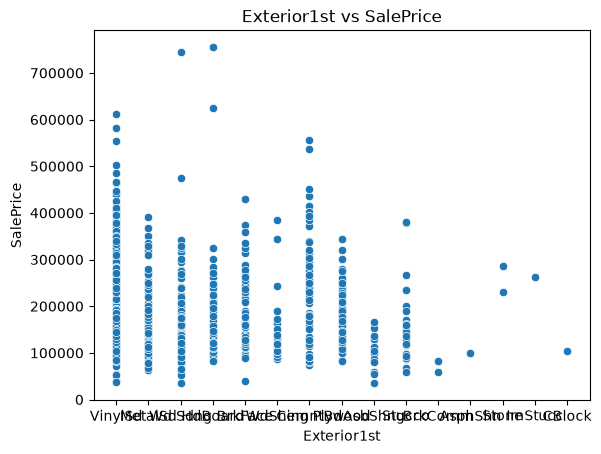

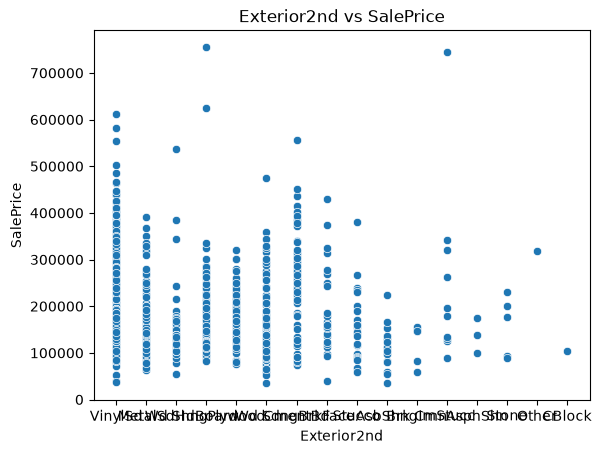

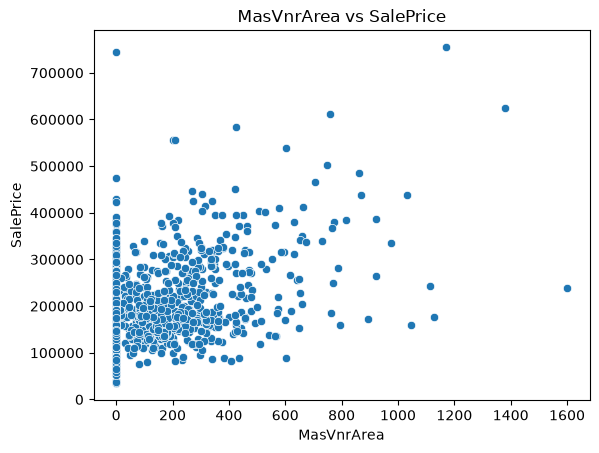

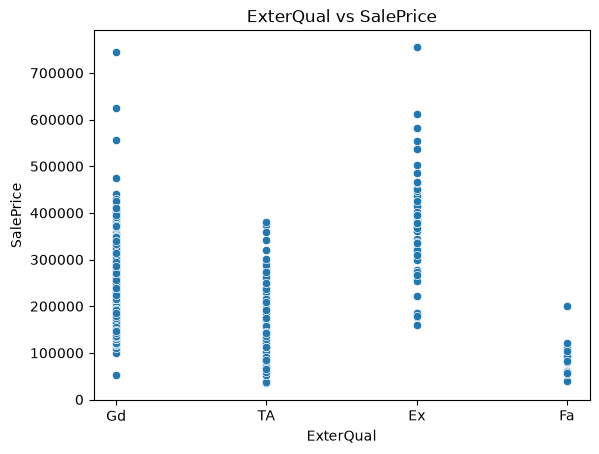

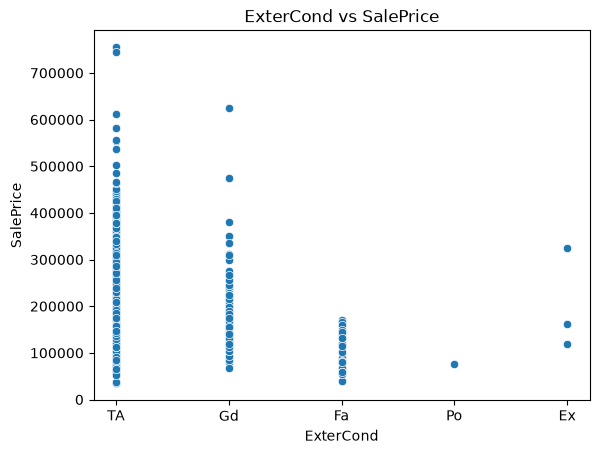

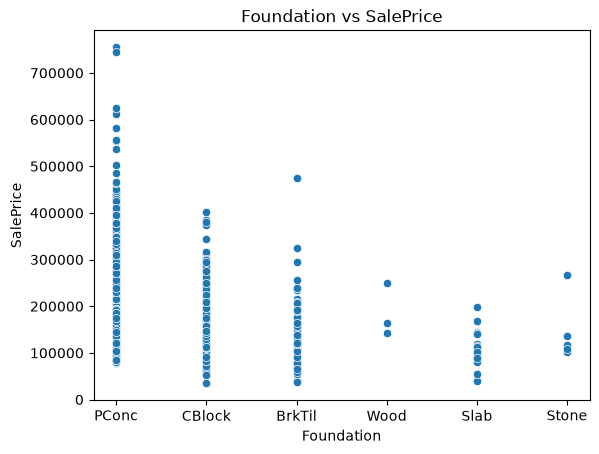

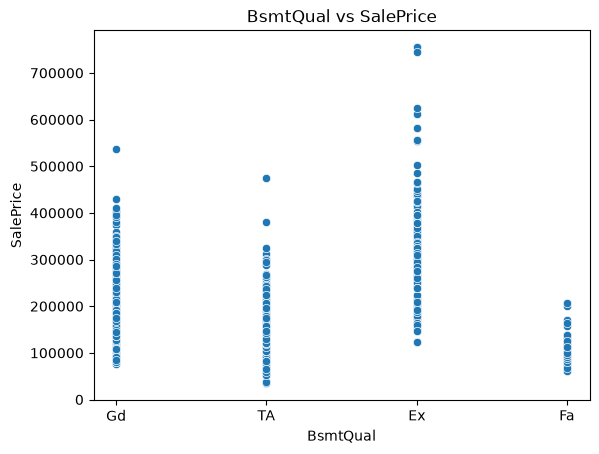

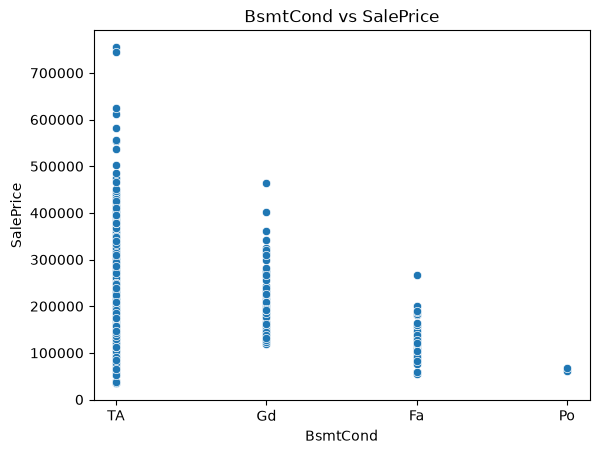

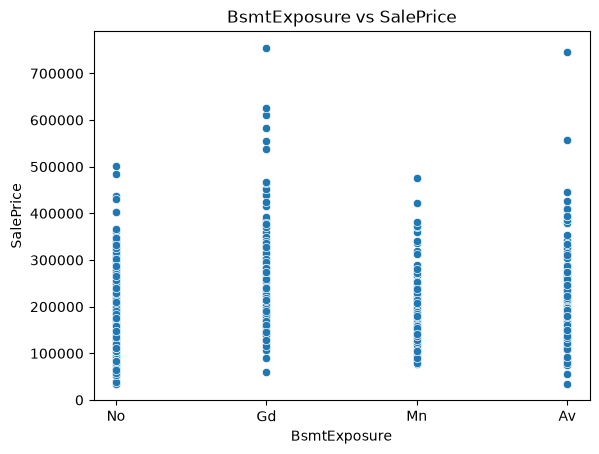

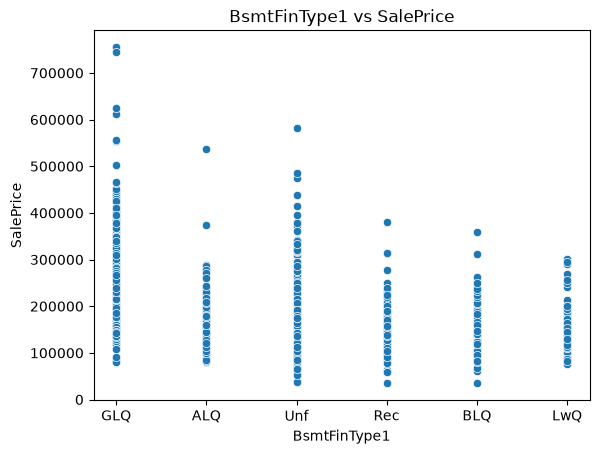

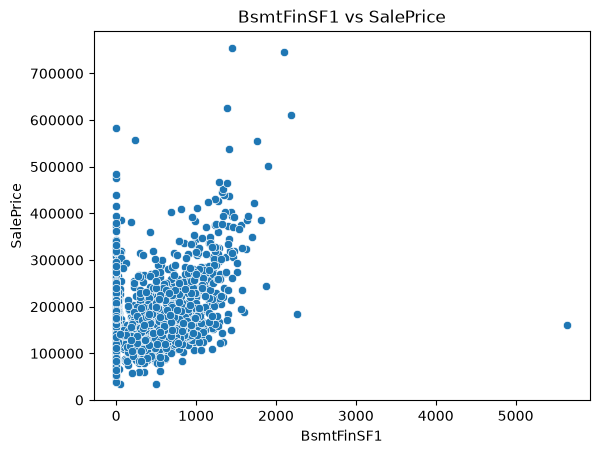

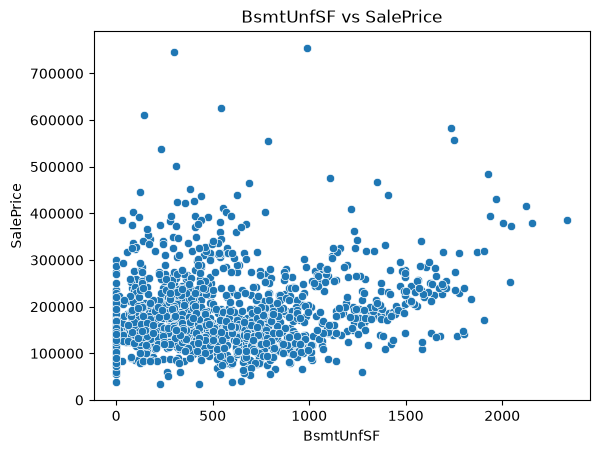

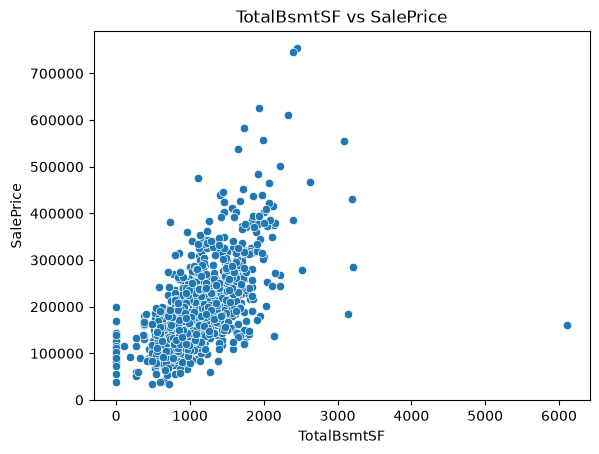

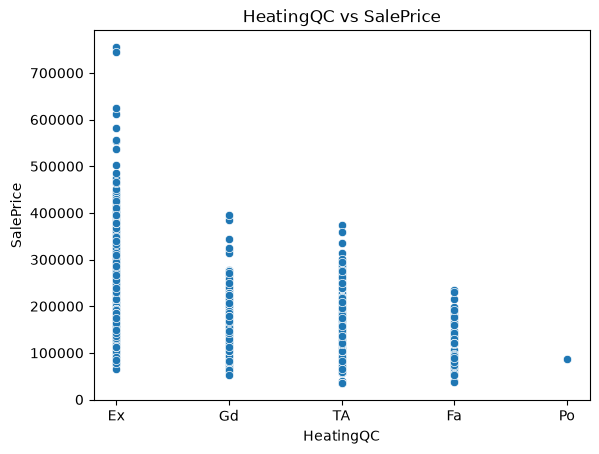

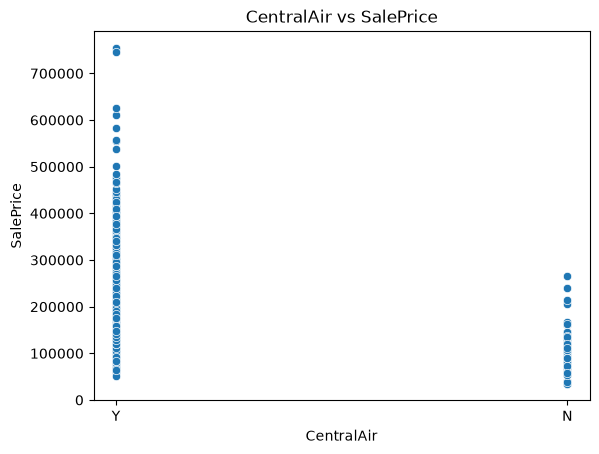

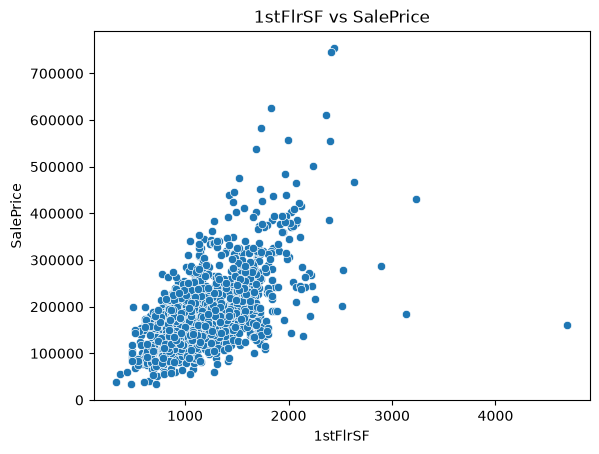

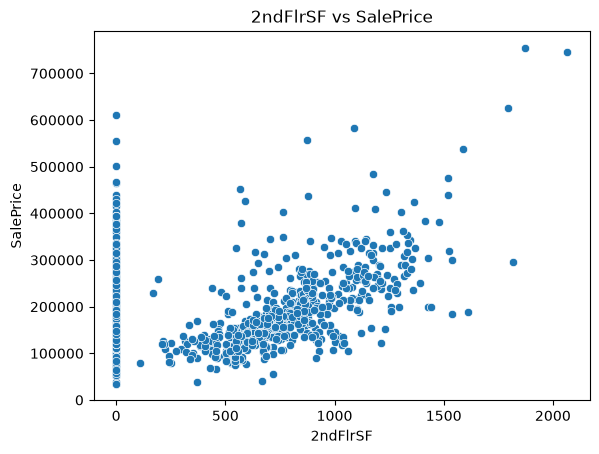

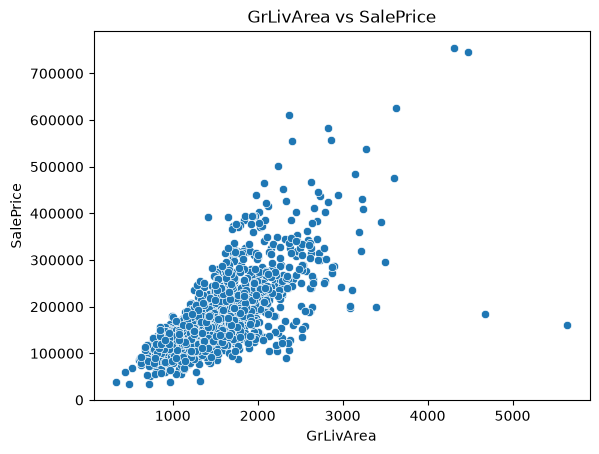

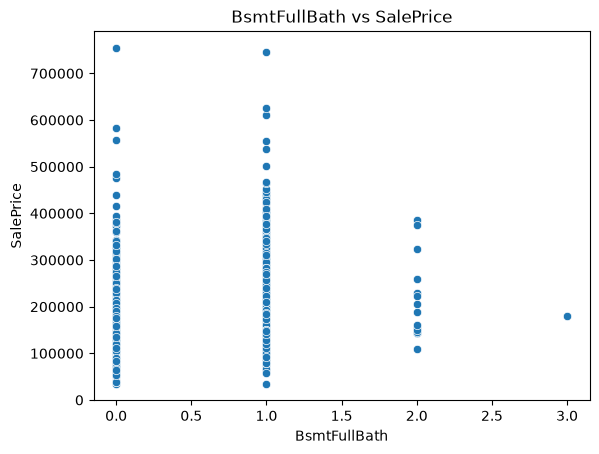

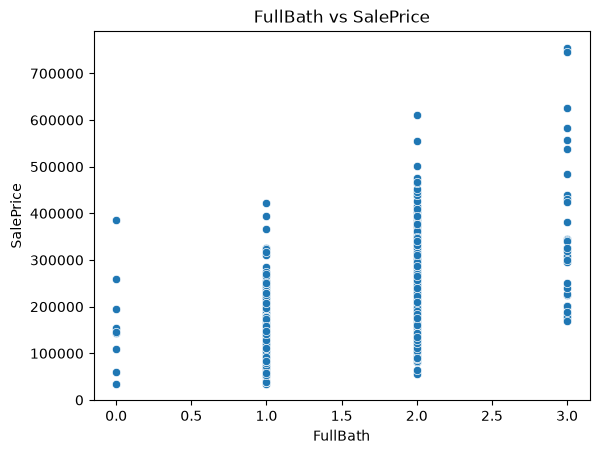

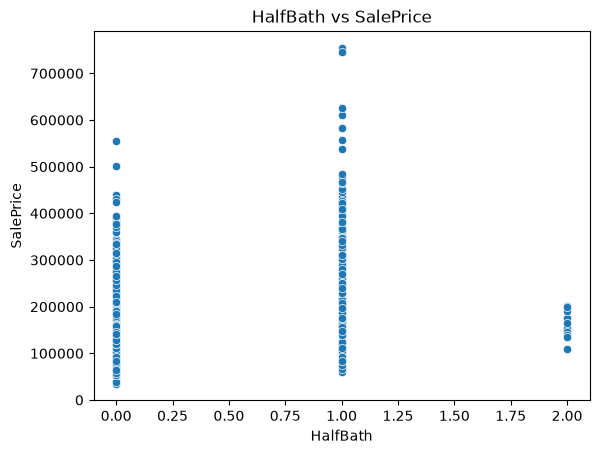

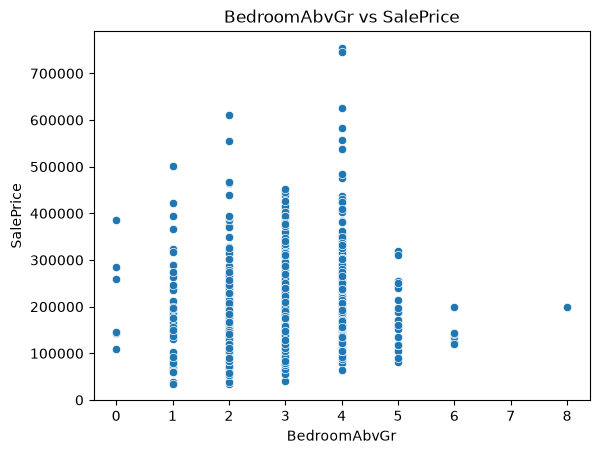

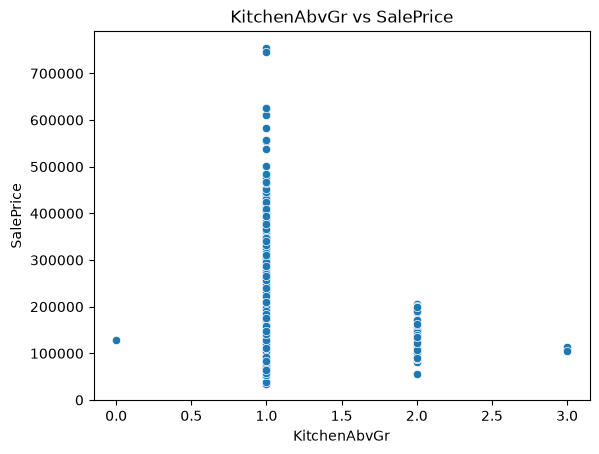

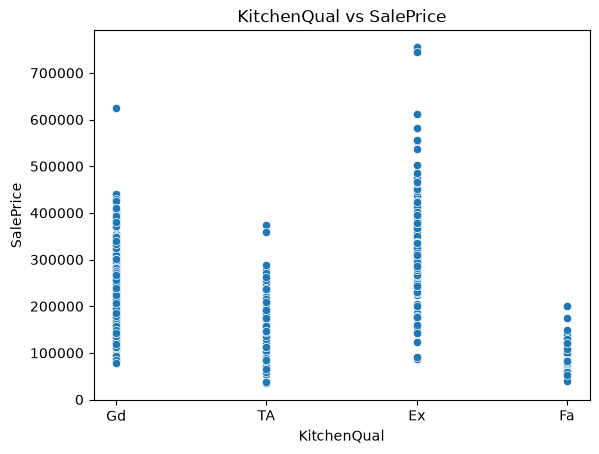

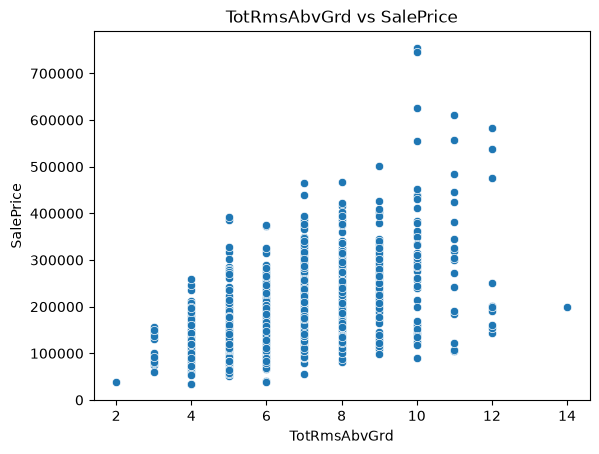

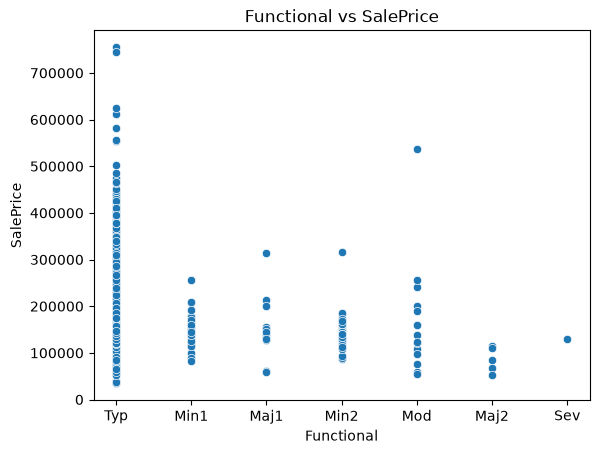

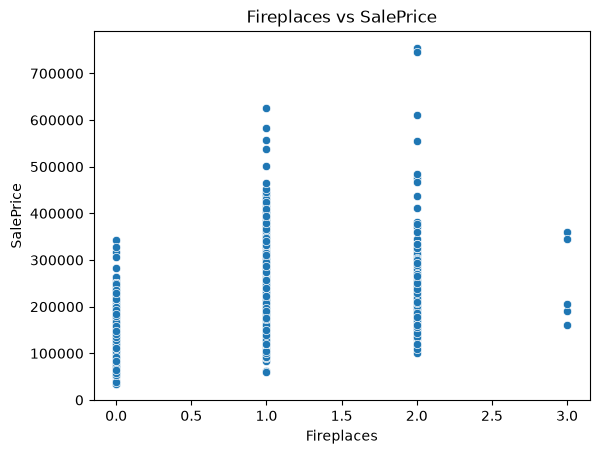

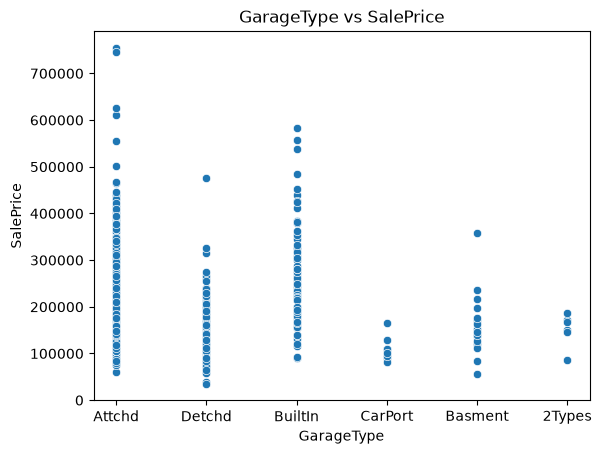

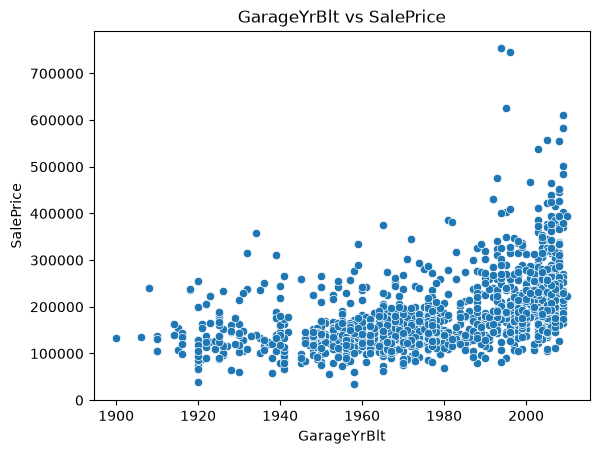

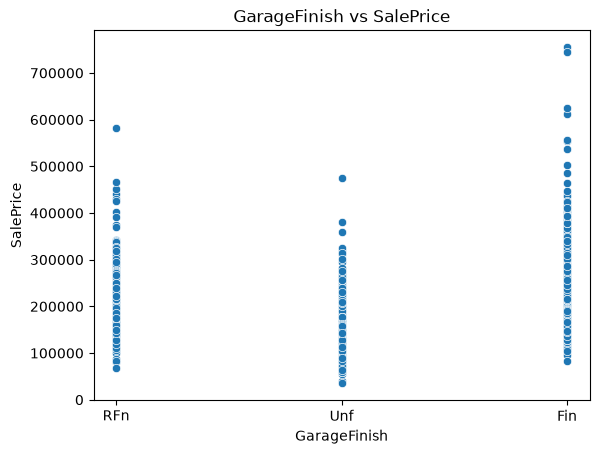

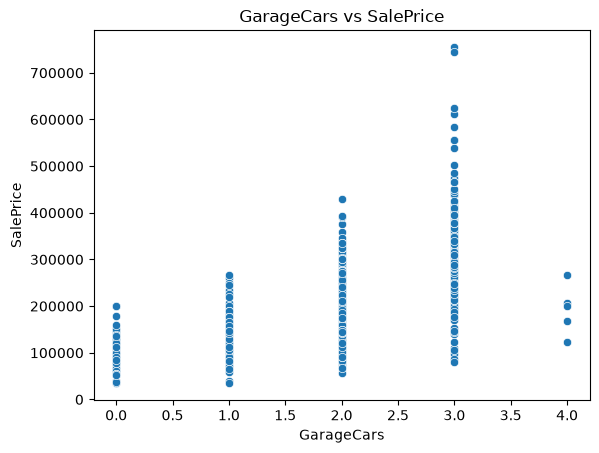

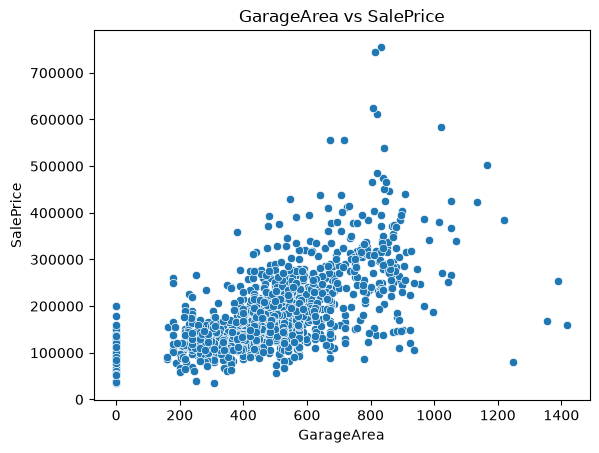

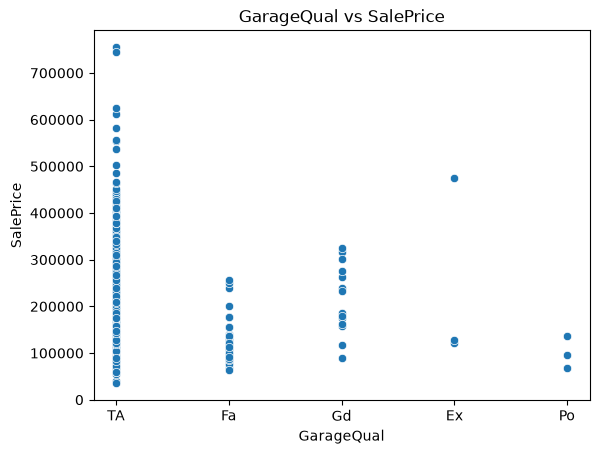

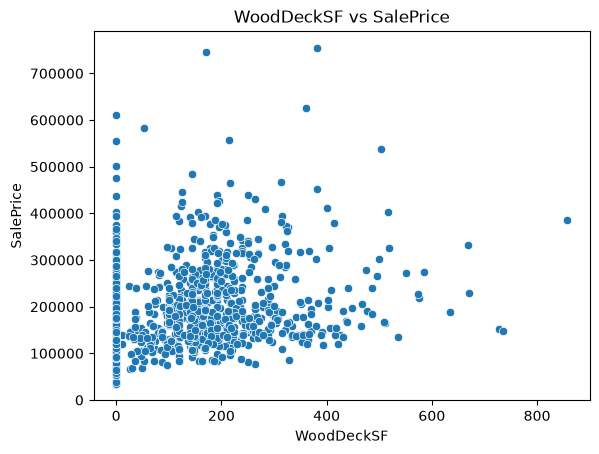

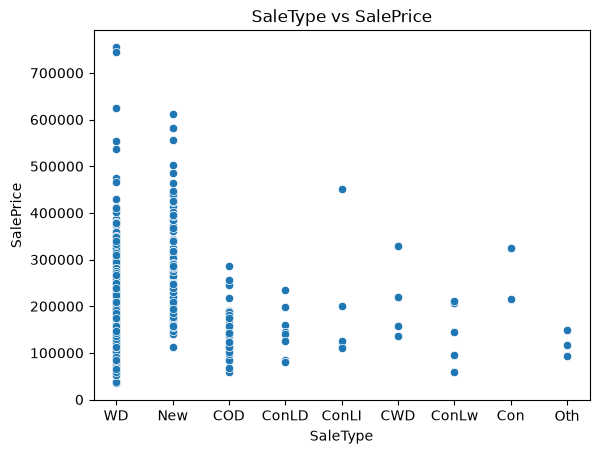

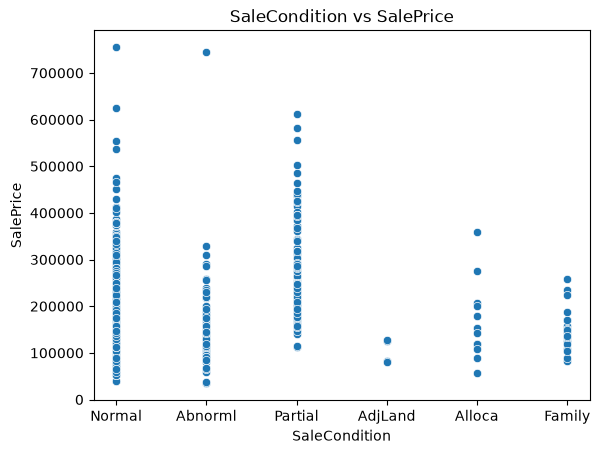

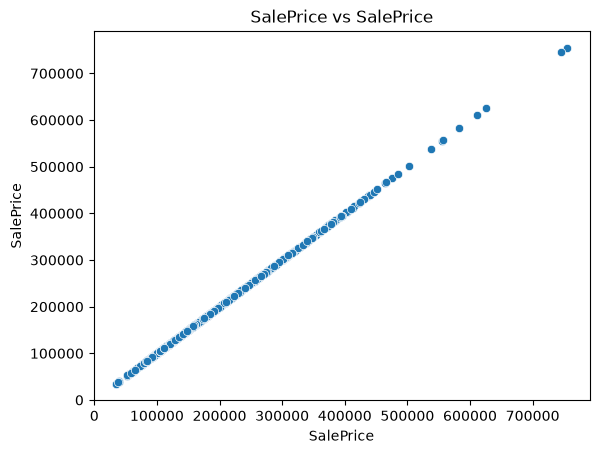

In [59]:
for col in train.columns.tolist():
    sns.scatterplot(data=train, x=col, y='SalePrice')
    plt.title(f'{col} vs SalePrice')
    plt.show()

In [60]:
from sklearn.preprocessing import StandardScaler

In [61]:
std = StandardScaler()
x_train_std = std.fit_transform(x_train)

In [62]:
x_test_std = std.transform(x_test)

In [63]:
test_std = std.transform(test)

In [64]:
from sklearn.preprocessing import PolynomialFeatures

In [65]:
poly = PolynomialFeatures(degree=2,include_bias=True)

In [66]:
x_train_pol=poly.fit_transform(x_train_std)
x_test_pol=poly.transform(x_test_std)
test_pol=poly.transform(test_std)

In [67]:
from sklearn.linear_model import LinearRegression

In [68]:
lr = LinearRegression()

In [69]:
lr.fit(x_train_pol,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [70]:
from sklearn.metrics import r2_score

In [71]:
y_pred = lr.predict(x_test_pol)

In [72]:
from sklearn.model_selection import cross_val_score,GridSearchCV

In [73]:
np.average(cross_val_score(lr,x_train_pol,y_train,scoring='r2',cv=5))

np.float64(0.5260964643128586)

In [74]:
r2_score(y_test,y_pred)

0.7051905839418642

In [75]:
from sklearn.tree import DecisionTreeRegressor

In [76]:
dt = DecisionTreeRegressor(max_depth=7,random_state=42)

In [77]:
dt.fit(x_train_pol,y_train)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",7
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf

In [78]:
dt_y_pred = dt.predict(x_test_pol)

In [79]:
r2_score(y_test,dt_y_pred)

0.7462802699160553

In [134]:
np.average(cross_val_score(dt,x_train_pol,y_train,scoring='r2',cv=5))

np.float64(0.6363141029368842)

In [136]:
dt.fit(x_train,y_train)
y_pred_dt = dt.predict(x_test)
print('r2 score',r2_score(y_test,y_pred_dt))
print(np.average(cross_val_score(dt,x_train,y_train,cv=5,scoring='r2')))

r2 score 0.8406118576785313
0.6501369320394224


In [81]:
from sklearn.linear_model import Ridge,ElasticNet,Lasso

In [82]:
rig = Ridge(alpha=0.00001)

In [88]:
rig.fit(x_train_std,y_train)
y_pred_rig = rig.predict(x_test_std)
print('r2 score',r2_score(y_test,y_pred_rig))
print(np.average(cross_val_score(rig,x_train_std,y_train,cv=5,scoring='r2')))

r2 score 0.847984599065891
0.8068326513804545


In [89]:
rig.fit(x_train_pol,y_train)
y_pred_rig = rig.predict(x_test_pol)
print('r2 score',r2_score(y_test,y_pred_rig))
print(np.average(cross_val_score(rig,x_train_pol,y_train,cv=5,scoring='r2')))

r2 score 0.7051954699122935
0.5261012137883907


In [123]:
lasso = Lasso(alpha=1.1 , max_iter=500)

In [128]:
lasso.fit(x_train_std,y_train)
y_pred_lasso = lasso.predict(x_test_std)
print('r2 score',r2_score(y_test,y_pred_lasso))
print(np.average(cross_val_score(lasso,x_train_std,y_train,cv=5,scoring='r2')))

r2 score 0.84825628385845
0.8070261064285891


C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.224e+11, tolerance: 6.967e+08
  model = cd_fast.enet_coordinate_descent(
C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.678e+11, tolerance: 5.374e+08
  model = cd_fast.enet_coordinate_descent(
C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.375e+11, toleranc

In [129]:
lasso.fit(x_train_pol,y_train)
y_pred_lasso = lasso.predict(x_test_pol)
print('r2 score',r2_score(y_test,y_pred_lasso))
print(np.average(cross_val_score(lasso,x_train_pol,y_train,cv=5,scoring='r2')))

C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.058e+09, tolerance: 6.967e+08
  model = cd_fast.enet_coordinate_descent(


r2 score 0.7525057687506419


C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.051e+09, tolerance: 5.374e+08
  model = cd_fast.enet_coordinate_descent(
C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.966e+09, tolerance: 5.720e+08
  model = cd_fast.enet_coordinate_descent(
C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.004e+09, toleranc

-0.184887451385833


C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.108e+09, tolerance: 5.796e+08
  model = cd_fast.enet_coordinate_descent(


In [130]:
lasso.fit(x_train,y_train)
y_pred_lasso = lasso.predict(x_test)
print('r2 score',r2_score(y_test,y_pred_lasso))
print(np.average(cross_val_score(lasso,x_train,y_train,cv=5,scoring='r2')))

r2 score 0.8486267860350655
0.8075726438511595


C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.260e+11, tolerance: 6.967e+08
  model = cd_fast.enet_coordinate_descent(
C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.179e+11, tolerance: 5.374e+08
  model = cd_fast.enet_coordinate_descent(
C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.178e+11, toleranc

In [142]:
eln = ElasticNet(alpha=0.5,l1_ratio=0.5,max_iter=10000)

In [143]:
eln.fit(x_train,y_train)
y_pred_eln = eln.predict(x_test)
print('r2 score',r2_score(y_test,y_pred_eln))
print(np.average(cross_val_score(eln,x_train,y_train,cv=5,scoring='r2')))

r2 score 0.8496123793918069
0.7976050954256146


In [150]:
eln.fit(x_train_std,y_train)
y_pred_eln = eln.predict(x_test_std)
print('r2 score',r2_score(y_test,y_pred_eln))
print(np.average(cross_val_score(eln,x_train_std,y_train,cv=5,scoring='r2')))

r2 score 0.8460834828351401
0.8255279604960567


In [145]:
eln.fit(x_train_pol,y_train)
y_pred_eln = eln.predict(x_test_pol)
print('r2 score',r2_score(y_test,y_pred_eln))
print(np.average(cross_val_score(eln,x_train_pol,y_train,cv=5,scoring='r2')))

C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.750e+10, tolerance: 6.967e+08
  model = cd_fast.enet_coordinate_descent(


r2 score 0.8419826230943452


C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.035e+10, tolerance: 5.374e+08
  model = cd_fast.enet_coordinate_descent(
C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.558e+10, tolerance: 5.720e+08
  model = cd_fast.enet_coordinate_descent(
C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.166e+10, toleranc

0.728576149747692


C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.982e+10, tolerance: 5.796e+08
  model = cd_fast.enet_coordinate_descent(
